# Entrenamiento de EfficientNetB0 — 5 clases de residuos

Este notebook entrena un clasificador de residuos con **EfficientNetB0** mediante *Transfer Learning*. Usa **exactamente el mismo dataset, cabecera, épocas y learning rates** que el notebook de MobileNetV3-Large, para que la comparación entre ambos modelos sea justa: cualquier diferencia se debe al modelo base.

**Clases que aprende el modelo (5):** `aluminio`, `carton`, `otros`, `plastico`, `vidrio`.

**Flujo del notebook:**
1.  Importar librerías, comprobar la GPU y definir rutas.
2.  Cargar las imágenes de `train/` y `test/` con generadores (con Data Augmentation en entrenamiento).
3.  Construir el modelo: EfficientNetB0 congelado + cabecera de clasificación propia.
4.  **Fase 1:** entrenar solo la cabecera (15 épocas, `learning_rate = 1e-3`).
5.  **Fase 2 (fine-tuning):** descongelar el 30 % superior del modelo base (20 épocas, `learning_rate = 1e-5`).
6.  Guardar el modelo en `.keras`, convertirlo a `.tflite` y graficar las curvas de entrenamiento.

**Archivos que genera:**
* `models/EfficientNetB0/modelo_residuos_EfficientNetB0_v1.keras`
* `models/EfficientNetB0/modelo_residuos_EfficientNetB0_v1.tflite`
* `reports/figures/curvas_entrenamiento_EfficientNetB0.png`

**Resultados de la ejecución guardada:** `val_accuracy` de **0.9614** al terminar la fase 1 y de **0.9663** al terminar el fine-tuning. El `.tflite` pesa 4.50 MB.

> 📁 Este notebook vive en `notebooks/EfficientNetB0/`, por eso las rutas parten de `Path("../..")` (dos niveles arriba = raíz del proyecto) y los modelos se leen/guardan en `models/EfficientNetB0/`.

### Importación de librerías

Reunimos al inicio todas las herramientas que usará el notebook:

* **`os` y `pathlib.Path`:** manejo de archivos y rutas multiplataforma.
* **`tensorflow`:** el motor de Deep Learning.
* **`ImageDataGenerator`:** lee las imágenes desde carpetas y les aplica transformaciones en tiempo real.
* **`EfficientNetB0`:** la red preentrenada que usaremos como base. Viene incluida en `tf.keras.applications`, así que no hace falta instalar nada extra.
* **`Dense`, `GlobalAveragePooling2D`, `Dropout`, `Model`:** piezas para construir la cabecera de clasificación.
* **`Adam`:** el optimizador que ajustará los pesos durante el entrenamiento.

In [3]:
import os
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

### Comprobación de GPU

Verifica si TensorFlow ve una **GPU NVIDIA** antes de empezar. EfficientNetB0 tiene más capas que MobileNetV3 (238 contra 187), así que entrenarlo en CPU sería bastante lento.

**En la ejecución guardada:** se usó una **NVIDIA GeForce RTX 4050 Laptop**, y cada época tomó unos 3 minutos.

In [4]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
print(f"¿TensorFlow detecta la GPU?: {len(gpus) > 0}")
if gpus:
    print(f"Detalles del dispositivo: {gpus[0]}")

¿TensorFlow detecta la GPU?: True
Detalles del dispositivo: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


### Configuración de rutas y verificación del dataset

Definimos dónde están los datos y dónde se guardará el modelo usando rutas **relativas**, para que el notebook funcione en cualquier computadora sin editar rutas a mano.

**¿Qué hace este código?**
1.  **`BASE_DIR = Path("../..")`:** sube dos niveles desde `notebooks/EfficientNetB0/` hasta la raíz del proyecto.
2.  **Rutas del dataset:** espera las carpetas `data/raw/waste_classification/train` y `data/raw/waste_classification/test`, cada una con una subcarpeta por clase.
3.  **`MODELS_DIR`:** apunta a `models/EfficientNetB0/`, la carpeta donde se guardan los modelos de esta arquitectura. Si no existe, la crea.
4.  **Verificación:** si no encuentra `train/` o `test/`, muestra un aviso para que coloques los datos manualmente (este notebook **no** descarga nada de Kaggle).

*Estructura esperada:*
```
data/raw/waste_classification/
├── train/
│   ├── clase_1/
│   └── ...
└── test/
    ├── clase_1/
    └── ...
```

In [5]:
# Definir rutas relativas a partir del directorio base
BASE_DIR = Path("../..") 
DATA_RAW_DIR = BASE_DIR / "data" / "raw"
DATASET_DIR = DATA_RAW_DIR / "waste_classification"
MODELS_DIR = BASE_DIR / "models" / "EfficientNetB0"

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

# Crear carpeta de modelos si no existe
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Verificación estricta de la existencia de los datos
if not TRAIN_DIR.exists() or not TEST_DIR.exists():
    print(f"⚠️ ¡Atención! No se encontró la estructura esperada en {DATASET_DIR}")
    print("Asegúrate de colocar tus carpetas 'train' y 'test' manualmente ahí.")
else:
    print(f"✅ Directorios de datos detectados correctamente en:\n - {TRAIN_DIR}\n - {TEST_DIR}")

✅ Directorios de datos detectados correctamente en:
 - ../data/raw/waste_classification/train
 - ../data/raw/waste_classification/test


### Carga de imágenes y aumento de datos (Data Augmentation)

En esta celda configuramos cómo "verá" el modelo las imágenes. El dataset ya viene separado en **dos carpetas**: `train/` para aprender y `test/` para validar, así que no hace falta dividirlo con `validation_split`.

**Dos generadores distintos:**
1.  **`train_datagen` (con Data Augmentation):** en cada época aplica cambios aleatorios para que el modelo no memorice las fotos:
    * Rotación de hasta 30° (`rotation_range`).
    * Desplazamiento horizontal y vertical del 20 % (`width_shift_range`, `height_shift_range`).
    * Zoom de hasta 30 % (`zoom_range`).
    * Volteo horizontal tipo espejo (`horizontal_flip`).
    * *Analogía:* es como entrenar a un portero lanzándole balones desde distintos ángulos y con distintos efectos, no siempre al mismo punto.
2.  **`test_datagen` (sin alteraciones):** las imágenes de validación deben llegar tal como son para medir el rendimiento real.

**Preprocesamiento:**
* **Sin `rescale`:** los generadores entregan los píxeles en su rango original (0–255). EfficientNetB0 de Keras incluye sus propias capas de reescalado y normalización al inicio del modelo, por lo que espera recibir los píxeles en 0–255. Si aplicáramos `rescale=1./255` encima, la imagen llegaría con valores incorrectos.

**Parámetros:**
* **`IMG_SIZE = (224, 224)`:** tamaño de entrada estándar de EfficientNetB0 (el mismo que MobileNetV3-Large, para comparar en igualdad de condiciones).
* **`BATCH_SIZE = 32`:** cuántas imágenes se procesan a la vez. Los generadores cargan lote por lote, sin meter todo el dataset en la RAM.
* **`shuffle=True`** en entrenamiento (mezclar evita que el modelo aprenda el orden de las carpetas) y **`shuffle=False`** en validación (mantiene el orden para poder comparar predicciones con etiquetas).

**Resultado:** 18 117 imágenes de entrenamiento y 4 534 de validación, repartidas en 5 clases. `NUM_CLASSES` se calcula automáticamente a partir de las carpetas encontradas, así que la última capa del modelo se adapta sola al número de clases.

In [6]:
# EfficientNetB0 espera imágenes de 224x224, igual que MobileNetV3-Large,
# lo que garantiza que ambos modelos reciben exactamente los mismos datos
# y la comparación de resultados es directamente válida.
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# NOTA IMPORTANTE sobre el preprocesamiento:
# A diferencia de modelos más antiguos (VGG, ResNet), EfficientNetB0 incluye
# su propia capa de reescalado interna (0-255 → [-1, 1]).
# Por eso NO se aplica rescale=1./255 en el generador, igual que con MobileNetV3.
# Aplicarlo por encima causaría que la imagen llegue al modelo con valores incorrectos.

# 1. Generador de Entrenamiento (CON Data Augmentation)
train_datagen = ImageDataGenerator(
    rotation_range=30,      
    width_shift_range=0.2,  
    height_shift_range=0.2, 
    zoom_range=0.3,         
    horizontal_flip=True    
)

# 2. Generador de Prueba/Validación (SIN alteraciones, solo para evaluar)
test_datagen = ImageDataGenerator()

print("Cargando set de ENTRENAMIENTO...")
train_gen = train_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True # Fundamental mezclar para entrenar
)

print("Cargando set de PRUEBA/VALIDACIÓN...")
val_gen = test_datagen.flow_from_directory(
    str(TEST_DIR),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # No se mezcla para poder evaluar ordenadamente
)

NUM_CLASSES = train_gen.num_classes
print(f"\nTotal de clases detectadas: {NUM_CLASSES}")
print(f"Diccionario de clases: {train_gen.class_indices}")

Cargando set de ENTRENAMIENTO...
Found 18117 images belonging to 5 classes.
Cargando set de PRUEBA/VALIDACIÓN...
Found 4534 images belonging to 5 classes.

Total de clases detectadas: 5
Diccionario de clases: {'aluminio': 0, 'carton': 1, 'otros': 2, 'plastico': 3, 'vidrio': 4}


### Carga del modelo base (Transfer Learning)

Aquí aplicamos **Transfer Learning**: reutilizamos un modelo que ya aprendió a "ver" en lugar de entrenar uno desde cero.

**¿Qué es EfficientNetB0?**
* Es el modelo más pequeño de la familia **EfficientNet** de Google (2019).
* Su idea central es el **escalado compuesto**: en lugar de hacer la red solo más profunda o solo más ancha, escala de forma equilibrada **profundidad, anchura y resolución**. Así logra más precisión con menos parámetros que arquitecturas anteriores.
* Usa bloques **MBConv** (los mismos *inverted residual* de MobileNetV2) con **Squeeze-and-Excitation** y la activación **swish**.
* Tamaño comparable al de MobileNetV3-Large: ~5.3 millones de parámetros contra ~5.4 millones.

**Configuración:**
1.  **`weights='imagenet'`:** pesos preentrenados en ImageNet.
2.  **`include_top=False`:** quitamos la capa original de 1000 clases.
3.  **`base_model.trainable = False`:** congelamos el modelo base para la primera fase.

**Resultado:** el modelo base tiene **238 capas**.

In [7]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0

# EfficientNetB0: modelo ligero de la familia EfficientNet de Google (2019).
# Su diseño se basa en un escalado compuesto (profundidad, anchura y resolución)
# que lo hace más eficiente que arquitecturas anteriores del mismo tamaño.
# 
# Comparativa con MobileNetV3-Large (nuestro modelo de referencia):
#   - Parámetros: ~5.3M vs ~5.4M (prácticamente iguales)
#   - Precisión en ImageNet (Top-1): ~77.1% vs ~75.2% (EfficientNetB0 ligeramente superior)
#   - El modelo base se obtiene directamente de tf.keras.applications,
#     igual que MobileNetV3. No se requiere ninguna instalación extra.
print("Cargando modelo EfficientNetB0...")

base_model = EfficientNetB0(
    weights='imagenet',       # Usamos el conocimiento previo de ImageNet
    include_top=False,        # ¡Crucial! Quitamos la capa de clasificación final (la "cabeza")
    input_shape=(224, 224, 3) # Definimos que entrarán imágenes de 224x224 con 3 canales (RGB)
)

# --- CONGELAMIENTO DE CAPAS ---
# "Congelamos" el modelo base. Esto significa que sus pesos (números internos)
# NO cambiarán durante la primera fase del entrenamiento.
# Esto nos permite usarlo solo como un "extractor de características" ultra avanzado.
base_model.trainable = False

print("✅ Modelo base cargado y congelado correctamente.")
print(f"   Estructura de entrada: {base_model.input_shape}")
print(f"   Total de capas: {len(base_model.layers)}")

Cargando modelo EfficientNetB0...


I0000 00:00:1791330131.265429    4429 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3501 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


✅ Modelo base cargado y congelado correctamente.
   Estructura de entrada: (None, 224, 224, 3)
   Total de capas: 238


### Construcción de la "cabecera" del modelo (el clasificador)

Tomamos el modelo base (EfficientNetB0) y le añadimos al final nuestra propia estructura de clasificación.

**Analogía:**
* **EfficientNetB0 (base):** son los **"ojos"**. Ya saben ver líneas, curvas y texturas complejas.
* **Nueva cabecera (head):** es el **"cerebro"** específico de nuestra tarea. Toma lo que ven los ojos y decide: "¿esto es cartón o vidrio?".

**Capas clave:**
1.  **`GlobalAveragePooling2D`:** "aplasta" los mapas de características 3D que salen del modelo base promediando cada canal. Reduce muchísimo la cantidad de datos (y de parámetros) frente a `Flatten`, algo vital para la Raspberry Pi.
2.  **`Dense(128, relu)`:** capa intermedia que aprende a combinar características visuales (ej.: "brillante" + "cilíndrico" = "lata").
3.  **`Dropout(0.3)`:** apaga al azar el 30 % de las neuronas en cada paso del entrenamiento. Obliga al modelo a no depender de una sola "pista" y reduce el *overfitting*.
4.  **`Dense(NUM_CLASSES, softmax)`:** capa final con una neurona por clase (5). **Softmax** convierte las salidas en **probabilidades** que suman 1 (ej.: 80 % plástico, 15 % vidrio, 5 % otros).

`model.summary()` imprime la tabla de capas y parámetros para verificar que todo quedó bien conectado.

**Importante para la comparación:** la cabecera es **idéntica** a la de MobileNetV3-Large y ShuffleNetV2. Si fuera más grande o más pequeña, no sabríamos si una diferencia de accuracy se debe al modelo base o a la cabecera.

In [8]:
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

# Construcción de la nueva cabecera del modelo.
# Se mantiene idéntica a la usada en MobileNetV3-Large para que la comparación
# de resultados sea justa: cualquier diferencia de accuracy se debe al backbone,
# no a una cabecera más o menos poderosa.
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x) # Capa intermedia para aprender patrones complejos
x = Dropout(0.3)(x) # Apaga el 30% de neuronas al azar para evitar memorización (overfitting)

# Capa de salida
output = Dense(NUM_CLASSES, activation='softmax')(x)

# Ensamblamos el modelo final
model = Model(inputs=base_model.input, outputs=output)

print("Arquitectura del modelo finalizada.")
model.summary() # Muestra un resumen para verificar que todo conecta bien

Arquitectura del modelo finalizada.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,214,184 (16.08 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

### Compilación y entrenamiento — Fase 1 (solo la cabecera)

En esta celda ocurren dos cosas:

1.  **Compilación (`model.compile`):** configuramos las "reglas" con las que el modelo aprenderá.
    * **Optimizador (Adam):** es el "profesor" que corrige al modelo. Cada vez que se equivoca, Adam ajusta los pesos para que la próxima vez lo haga mejor.
    * **Learning rate (`1e-3`):** la velocidad de aprendizaje. *0.001* es un valor estándar y seguro: si es muy alto el modelo no converge; si es muy bajo tarda una eternidad.
    * **Loss (`categorical_crossentropy`):** la "puntuación de error" que el modelo intenta bajar. Se usa la versión *categorical* porque hay más de dos clases y las etiquetas vienen en formato *one-hot*.
    * **Metrics (`accuracy`):** porcentaje de aciertos.

2.  **Entrenamiento (`model.fit`):**
    * **`epochs=15`:** el modelo recorre el dataset de entrenamiento completo 15 veces.
    * **`validation_data=val_gen`:** al final de cada época se evalúa con imágenes que nunca usa para aprender, para saber si realmente generaliza o solo memoriza.
    * Como el modelo base está **congelado**, en esta fase solo se ajustan los pesos de la cabecera nueva.

**Cómo leer la salida:** `accuracy`/`loss` son del set de entrenamiento y `val_accuracy`/`val_loss` del de validación. Si `accuracy` sube mucho más que `val_accuracy`, es señal de *overfitting*.

**Resultado de la ejecución guardada:** tras 15 épocas, `accuracy` = 0.9614 y **`val_accuracy` = 0.9614** (`val_loss` = 0.1415). Ya en la fase 1 supera a MobileNetV3-Large (0.9488).

In [9]:
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

# COMPILACIÓN DEL MODELO
# Definimos cómo va a aprender la red neuronal
print("Compilando el modelo con optimizador Adam...")

model.compile(
    optimizer=Adam(learning_rate=1e-3), # 0.001: Velocidad de aprendizaje inicial estándar
    loss='categorical_crossentropy',    # Obligatorio para clasificación de múltiples clases (>2)
    metrics=['accuracy']                # Queremos monitorear qué tan preciso es (0.0 a 1.0)
)

# ENTRENAMIENTO — FASE 1
# En esta fase solo entrenamos la cabecera que agregamos.
# El backbone (EfficientNetB0) permanece congelado, actuando como extractor de características.
print("\nIniciando entrenamiento (Fase 1 - Cabecera)...")
print("   Nota: Esto puede tardar dependiendo de tu hardware (CPU vs GPU).")

history = model.fit(
    train_gen,               # Datos de entrenamiento (con data augmentation)
    validation_data=val_gen, # Datos de validación (para examen final de cada época)
    epochs=15,               # Número de vueltas completas al dataset
    verbose=1                # Muestra una barra de progreso animada
)

print("¡Entrenamiento fase 1 completado!")

Compilando el modelo con optimizador Adam...

Iniciando entrenamiento (Fase 1 - Cabecera)...
   Nota: Esto puede tardar dependiendo de tu hardware (CPU vs GPU).
Epoch 1/15


I0000 00:00:1791330133.383889    4429 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1791330139.022774    5666 service.cc:153] XLA service 0x7f170c0586a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791330139.022794    5666 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791330139.220747    5666 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791330140.467904    5666 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791330140.735746    5666 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_16022__.255
E0000 00:00:1791330142.395188    5666 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup 

  1/567 ━━━━━━━━━━━━━━━━━━━━ 3:26:50 22s/step - accuracy: 0.1875 - loss: 1.6512

I0000 00:00:1791330155.251975    5666 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 92/567 ━━━━━━━━━━━━━━━━━━━━ 2:28 313ms/step - accuracy: 0.6008 - loss: 0.9815

...

100/567 ━━━━━━━━━━━━━━━━━━━━ 2:27 316ms/step - accuracy: 0.6117 - loss: 0.9598

I0000 00:00:1791330188.025507    5664 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_16022__.255
E0000 00:00:1791330188.823528    5664 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791330190.192143    5664 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791330191.170500    5664 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


567/567 ━━━━━━━━━━━━━━━━━━━━ 0s 339ms/step - accuracy: 0.7774 - loss: 0.5995

E0000 00:00:1791330378.513658    5663 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791330379.284110    5663 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791330380.018754    5663 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


567/567 ━━━━━━━━━━━━━━━━━━━━ 250s 404ms/step - accuracy: 0.8474 - loss: 0.4339 - val_accuracy: 0.9142 - val_loss: 0.2524
Epoch 2/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 185s 326ms/step - accuracy: 0.9012 - loss: 0.2795 - val_accuracy: 0.9327 - val_loss: 0.2032
Epoch 3/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 189s 334ms/step - accuracy: 0.9157 - loss: 0.2382 - val_accuracy: 0.9345 - val_loss: 0.1936
Epoch 4/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 201s 355ms/step - accuracy: 0.9260 - loss: 0.2075 - val_accuracy: 0.9435 - val_loss: 0.1789
Epoch 5/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 187s 330ms/step - accuracy: 0.9365 - loss: 0.1768 - val_accuracy: 0.9457 - val_loss: 0.1675
Epoch 6/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 176s 310ms/step - accuracy: 0.9406 - loss: 0.1687 - val_accuracy: 0.9486 - val_loss: 0.1643
Epoch 7/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 195s 343ms/step - accuracy: 0.9435 - loss: 0.1581 - val_accuracy: 0.9482 - val_loss: 0.1638
Epoch 8/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 186s 328ms/step - accuracy: 0.9464 - loss: 0.14

### Fine-tuning (Fase 2: afinamiento de precisión)

Hasta ahora solo entrenamos la "cabecera". El "cuerpo" (EfficientNetB0) seguía congelado con lo que aprendió en ImageNet. Ahora desbloqueamos una parte para que se adapte mejor a *nuestras* imágenes de residuos.

**Estrategia "70/30":**
1.  **Descongelar parcialmente:** se permite que el **30 % superior** de las capas del modelo base aprenda.
    * *¿Por qué?* Las primeras capas detectan bordes y texturas simples (útiles para cualquier imagen). Las últimas detectan formas complejas, y esas sí conviene adaptarlas para reconocer botellas aplastadas o cartón arrugado.
2.  **Congelar el 70 % inferior:** se mantiene intacto para no perder estabilidad.
    * En este modelo: **238 capas** en total → **166 congeladas** y **72 entrenables**.

**⚠️ Cambio crítico: learning rate**
* Bajamos de `1e-3` a **`1e-5`** (100 veces más pequeño).
* **Razón:** el modelo ya sabe bastante, ahora solo queremos **ajustes microscópicos**. Con una tasa alta se destruiría el conocimiento previo (*catastrophic forgetting*).
* Es **obligatorio volver a compilar** después de cambiar qué capas son entrenables; si no, Keras ignora el cambio.

**Entrenamiento:** 20 épocas más sobre los mismos generadores. El objeto `history_fine` guarda la evolución de esta fase.

**Resultado de la ejecución guardada:** tras 20 épocas, `accuracy` = 0.9699 y **`val_accuracy` = 0.9663** (`val_loss` = 0.1212).

Se usa la **misma proporción 70/30** que en MobileNetV3-Large para que la comparación sea justa.

In [10]:
import tensorflow as tf

print("Iniciando configuración de Fine-Tuning...")

# Descongelamos todo el modelo base primero
base_model.trainable = True

# Decidimos dónde cortar: Congelaremos el 70% inferior.
# Se usa la misma proporción que en MobileNetV3-Large para que la comparación sea justa.
fine_tune_at = int(len(base_model.layers) * 0.7)

# Congelamos las capas anteriores al punto de corte
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"   Total de capas en EfficientNetB0: {len(base_model.layers)}")
print(f"   Capas congeladas (70%): {fine_tune_at}")
print(f"   Capas entrenables (30%): {len(base_model.layers) - fine_tune_at}")

# RE-COMPILACIÓN (Obligatorio después de descongelar)
# ¡IMPORTANTE! Usamos un Learning Rate MUY BAJO (1e-5)
# Esto es para hacer "micro-ajustes" sin romper los pesos ya aprendidos.
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\nIniciando Fase 2 de Entrenamiento (Fine-Tuning)...")
print("   Nota: Esto tomará más tiempo por época, pero mejorará la precisión.")

# Entrenamiento final
history_fine = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20 # Entrenamos por 20 épocas más
)

print("¡Entrenamiento completo finalizado!")

Iniciando configuración de Fine-Tuning...
   Total de capas en EfficientNetB0: 238
   Capas congeladas (70%): 166
   Capas entrenables (30%): 72

Iniciando Fase 2 de Entrenamiento (Fine-Tuning)...
   Nota: Esto tomará más tiempo por época, pero mejorará la precisión.
Epoch 1/20


I0000 00:00:1791333014.013015    5665 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_85972__.315


179/567 ━━━━━━━━━━━━━━━━━━━━ 1:49 283ms/step - accuracy: 0.8082 - loss: 0.6773

I0000 00:00:1791333077.868926    5665 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_85972__.315


567/567 ━━━━━━━━━━━━━━━━━━━━ 232s 366ms/step - accuracy: 0.8597 - loss: 0.4374 - val_accuracy: 0.9252 - val_loss: 0.2466
Epoch 2/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 189s 334ms/step - accuracy: 0.9069 - loss: 0.2706 - val_accuracy: 0.9360 - val_loss: 0.2149
Epoch 3/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 174s 306ms/step - accuracy: 0.9188 - loss: 0.2358 - val_accuracy: 0.9418 - val_loss: 0.1969
Epoch 4/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 182s 321ms/step - accuracy: 0.9289 - loss: 0.2077 - val_accuracy: 0.9442 - val_loss: 0.1819
Epoch 5/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 188s 331ms/step - accuracy: 0.9325 - loss: 0.1922 - val_accuracy: 0.9506 - val_loss: 0.1691
Epoch 6/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 178s 314ms/step - accuracy: 0.9397 - loss: 0.1724 - val_accuracy: 0.9519 - val_loss: 0.1635
Epoch 7/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 172s 304ms/step - accuracy: 0.9420 - loss: 0.1611 - val_accuracy: 0.9532 - val_loss: 0.1543
Epoch 8/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 180s 318ms/step - accuracy: 0.9479 - loss: 0.14

### Guardado del modelo (la "copia maestra")

Una vez terminado el entrenamiento guardamos todo lo que aprendió el modelo en un solo archivo.

**Detalles técnicos:**
1.  **Formato `.keras`:** es el formato nativo de **Keras 3**. Es un archivo comprimido (zip) que contiene:
    * La arquitectura (las capas que diseñamos).
    * Los pesos (lo que aprendió).
    * La configuración del optimizador (para poder reanudar el entrenamiento si hiciera falta).
2.  **Ruta de salida:** `models/EfficientNetB0/modelo_residuos_EfficientNetB0_v1.keras`. Si la carpeta no existe (por ejemplo, porque no se bajó de git), el código la crea.
3.  Al final imprime la **ruta absoluta**, para no tener dudas de dónde quedó el archivo.

**Nota:** este archivo es el respaldo de alta calidad. Para la Raspberry Pi se usa la versión `.tflite` que se genera en la siguiente celda.

In [11]:
import os

# GUARDADO DEL MODELO

# Aseguramos que el directorio de modelos exista
# Si un compañero borró la carpeta 'models' o no se bajó de git, esto la crea.
if not MODELS_DIR.exists():
    print(f"La carpeta {MODELS_DIR} no existía. Creándola...")
    MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Definimos la ruta completa.
# Usamos la extensión .keras que es el estándar actual más seguro y ligero que .h5
model_save_path = MODELS_DIR / "modelo_residuos_EfficientNetB0_v1.keras"

print(f"Guardando modelo maestro en: {model_save_path} ...")
model.save(model_save_path)

# Confirmación visual con ruta absoluta para evitar confusiones sobre dónde se guardó el modelo
print(f"¡Éxito! El archivo está listo.")
print(f"   Ruta absoluta: {model_save_path.resolve()}")

Guardando modelo maestro en: ../models/modelo_residuos_EfficientNetB0_v1.keras ...
¡Éxito! El archivo está listo.
   Ruta absoluta: /home/eduarduar/dev/EntrenamientoIA/models/modelo_residuos_EfficientNetB0_v1.keras


### Conversión a TensorFlow Lite (IoT y Edge AI)

Este paso es necesario para ejecutar el modelo en la Raspberry Pi de forma fluida: convertimos el modelo `.keras` al formato `.tflite`.

**¿Qué hace la conversión?**
1.  **Traducción:** `TFLiteConverter.from_keras_model` reescribe el modelo como un grafo de operaciones simplificado que el intérprete de TensorFlow Lite ejecuta eficientemente en procesadores ARM.
2.  **Cuantización (`tf.lite.Optimize.DEFAULT`):**
    * Aplica *dynamic range quantization*: los **pesos** se guardan como enteros de **8 bits** en lugar de flotantes de 32 bits.
    * *Resultado:* el archivo pesa aproximadamente 4 veces menos y la inferencia en CPU suele ser más rápida.
    * *Impacto:* la precisión normalmente cambia muy poco, pero conviene verificarla evaluando el `.tflite` (ver `tests/Evaluate_tflite.py` / `tests/comparar_modelos_inferencia.py`).
3.  **Guardado:** escribe el archivo en `models/EfficientNetB0/modelo_residuos_EfficientNetB0_v1.tflite`.
4.  **Reporte de optimización:** compara el tamaño del `.keras` contra el `.tflite`.

**Resultado de la ejecución guardada:** 41.67 MB (`.keras`) → **4.50 MB** (`.tflite`), es decir, **89.20 % menos**.

> ℹ️ El `.keras` pesa más que solo los pesos del modelo porque también incluye el estado del optimizador Adam; por eso la reducción es mayor al 75 % esperado solo por la cuantización.

Es el `.tflite` más pesado de los tres modelos comparados (MobileNetV3-Large: 3.24 MB, ShuffleNetV2: 1.50 MB), algo a considerar en la latencia de la Raspberry Pi.

In [12]:
print("Iniciando conversión a TFLite...")

# Cargar el convertidor desde el modelo Keras en memoria
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Aplicar optimizaciones — Cuantización
# Esto reduce el tamaño del archivo y acelera la inferencia en la Raspberry Pi
# sin sacrificar casi nada de precisión.
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Realizar la conversión
tflite_model = converter.convert()

# Guardar el archivo .tflite
tflite_save_path = MODELS_DIR / "modelo_residuos_EfficientNetB0_v1.tflite"

with open(tflite_save_path, "wb") as f:
    f.write(tflite_model)

print(f"Modelo TFLite guardado en: {tflite_save_path}")

# --- COMPARACIÓN DE TAMAÑOS ---
# Esto es meramente para mostrar en el reporte final
keras_size = os.path.getsize(model_save_path) / (1024 * 1024)
tflite_size = os.path.getsize(tflite_save_path) / (1024 * 1024)

print(f"\nReporte de Optimización:")
print(f"   Tamaño Original (.keras): {keras_size:.2f} MB")
print(f"   Tamaño Optimizado (.tflite): {tflite_size:.2f} MB")
print(f"   Reducción de tamaño: {((keras_size - tflite_size) / keras_size) * 100:.2f}% menos")

Iniciando conversión a TFLite...
INFO:tensorflow:Assets written to: /tmp/tmphpg6jz3q/assets


INFO:tensorflow:Assets written to: /tmp/tmphpg6jz3q/assets


Saved artifact at '/tmp/tmphpg6jz3q'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  139730996069392: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139730996073808: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139731195467856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139731195468240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139731195467088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139731195469008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139731195465936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139731195469392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139731195471120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139731195471312: TensorSpec(shape=(), dtype=tf.resource, name=None

W0000 00:00:1791336649.500208    4429 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791336649.500244    4429 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1791336649.501588    4429 reader.cc:83] Reading SavedModel from: /tmp/tmphpg6jz3q
I0000 00:00:1791336649.513257    4429 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1791336649.513277    4429 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmphpg6jz3q
I0000 00:00:1791336649.610444    4429 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1791336649.625091    4429 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1791336650.106442    4429 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmphpg6jz3q
I0000 00:00:1791336650.237636    4429 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 736058 microseconds.


### Curvas de entrenamiento (accuracy y loss)

Para documentar el entrenamiento unimos el historial de las **dos fases** (`history` + `history_fine`) y lo graficamos en una sola figura.

**¿Qué muestra la gráfica?**
* **Izquierda — Accuracy:** aciertos en entrenamiento (`Train`) y en validación (`Val`) época por época.
* **Derecha — Loss:** el error en entrenamiento y en validación.
* **Línea roja punteada:** marca la época 15, donde termina la fase 1 y empieza el *fine-tuning*.

**Cómo interpretarla:**
* Si ambas curvas de accuracy suben juntas y las de loss bajan juntas, el modelo está generalizando bien.
* Si `Train Accuracy` sigue subiendo mientras `Val Accuracy` se estanca o baja, hay *overfitting*.
* Es normal ver un pequeño salto justo después de la línea roja: al descongelar capas el modelo vuelve a ajustarse.

La figura se guarda en `reports/figures/curvas_entrenamiento_EfficientNetB0.png` para usarla en el reporte comparativo de EfficientNetB0.

> ℹ️ Aquí el inicio del fine-tuning está fijo en `fine_tune_start = 15`; si cambias las épocas de la fase 1, actualiza también este valor.

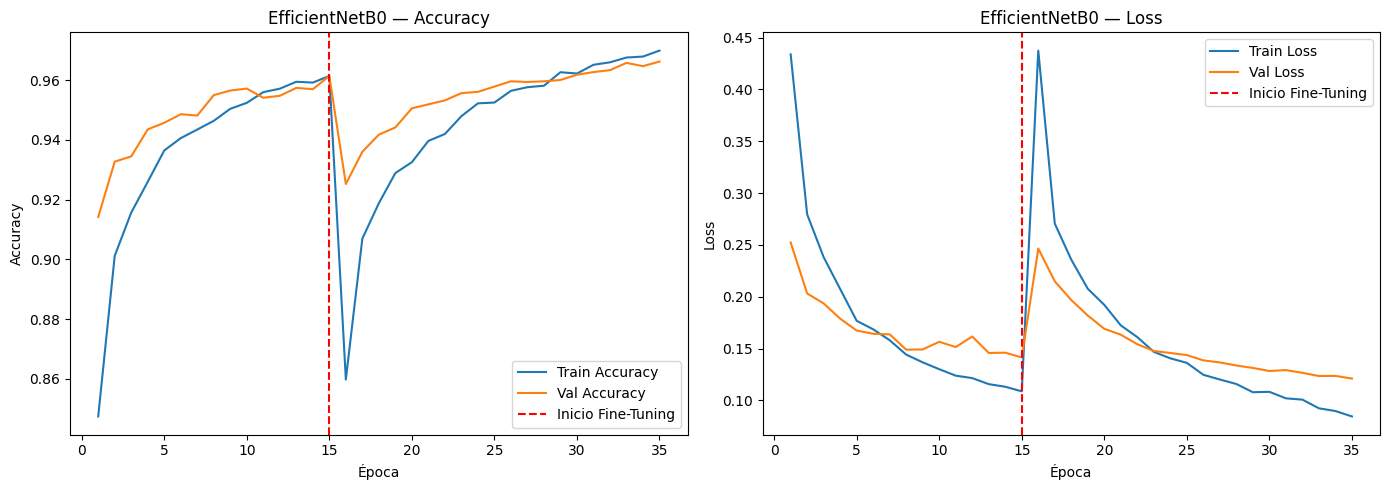

Gráfica guardada.


In [13]:
import matplotlib.pyplot as plt

# Unir el historial de ambas fases para graficar la evolución completa del entrenamiento.
# Esto permite ver en una sola gráfica cómo mejoró el modelo en la fase de cabecera
# y luego en el fine-tuning, con una línea vertical que marca el cambio de fase.
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']

epochs_total = range(1, len(acc) + 1)
fine_tune_start = 15  # Época donde empieza el fine-tuning

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_total, acc, label='Train Accuracy')
ax1.plot(epochs_total, val_acc, label='Val Accuracy')
ax1.axvline(x=fine_tune_start, color='r', linestyle='--', label='Inicio Fine-Tuning')
ax1.set_title('EfficientNetB0 — Accuracy')
ax1.set_xlabel('Época')
ax1.set_ylabel('Accuracy')
ax1.legend()

ax2.plot(epochs_total, loss, label='Train Loss')
ax2.plot(epochs_total, val_loss, label='Val Loss')
ax2.axvline(x=fine_tune_start, color='r', linestyle='--', label='Inicio Fine-Tuning')
ax2.set_title('EfficientNetB0 — Loss')
ax2.set_xlabel('Época')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()

FIGURES_DIR = BASE_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / "curvas_entrenamiento_EfficientNetB0.png", dpi=150)
plt.show()
print("Gráfica guardada.")